In [34]:
from typing import Annotated, TypedDict, List
from dotenv import load_dotenv, find_dotenv
from langchain_groq import ChatGroq
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage, SystemMessage
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.graph.message import add_messages

load_dotenv(find_dotenv())


True

Chatbot Creating New Memories(with Duplication)


In [35]:
from pydantic import BaseModel, Field


In [36]:
# 2. Initialize LLM
llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0.7,
)


In [ ]:
# class memorydecision(BaseModel):
#     should_write: bool = Field(description="whether to store any memories")
#     memories: List[str] = Field(default_factory=list, description="atomic user memories to store")


In [37]:
class Memoryitem(BaseModel):
    text: str = Field(description="atomic user memory as a short sentences")
    is_new :bool= Field( description="true if this memeory is new and should be stored .false if duplicate/already in memeory")


In [38]:
class memorydecision(BaseModel):
    should_write: bool = Field(description="whether to store any memories")
    memories: List[Memoryitem] = Field(default_factory=list, description="atomic user memories to store")


In [39]:
memory_extractor = llm.with_structured_output(memorydecision)


In [40]:
from langgraph.store.memory import InMemoryStore
from langchain_core.runnables import RunnableConfig
from langgraph.store.base import BaseStore

store = InMemoryStore()


Chatbot Creating New Memories(without Duplication)



In [45]:
MEMORY_PROMPT = """You are a memory extraction assistant.

The user already has these stored memories:
{user_details_content}

From the new user message, extract any LONG-TERM memories worth storing (identity, preferences, ongoing projects).
For each memory, mark is_new=True if it does NOT already exist in the stored memories above, or is_new=False if it's a duplicate.
Return should_write=False if nothing is worth storing."""


In [ ]:
import uuid

def chat_creates_memory_node(state: MessagesState, config: RunnableConfig, store: BaseStore):

    user_id = config["configurable"]["user_id"]

    namespace = ("user", user_id, "details")

    # A) Load existing memories
    existing_items = store.search(namespace)
    existing_texts = [it.value.get("data", "") for it in existing_items if it.value.get("data")]
    user_details_content = "\n".join(f"- {t}" for t in existing_texts) if existing_texts else "(empty)"

    # B) Latest user message
    last_text = state["messages"][-1]

    # C) LLM extracts memories + marks new vs duplicate
    decision = memory_extractor.invoke(
        [
            SystemMessage(content=MEMORY_PROMPT.format(user_details_content=user_details_content)),
            {"role": "user", "content": f"USER MESSAGE:\n{last_text}"},
        ]
    )

    # D) Store ONLY new memories
    if decision.should_write:
        for mem in decision.memories:
            if mem.is_new:
                store.put(namespace, str(uuid.uuid4()), {"data": mem.text})

    return {"messages": [{"role": "assistant", "content": "Noted."}]}

In [ ]:
# import uuid

# def remember_onlynode(state: MessagesState, config: RunnableConfig, store: BaseStore):
#     user_id = config["configurable"]["user_id"]

#     namespace = ("user", user_id, "details")

#     last_msg = state["messages"][-1].content

#     decision: memorydecision = memory_extractor.invoke(
#         [
#             SystemMessage(
#                 content=(
#                     "Extract LONG-TERM memories from the user's message.\n"
#                     "Only store stable, user-specific info (identity, preferences, ongoing projects).\n"
#                     "Do NOT store transient info.\n"
#                     "Return should_write=false if nothing is worth storing.\n"
#                     "Each memory should be a short atomic sentence."
#                 )
#             ),
#             {"role": "user", "content": last_msg},
#         ]
#     )

#     if decision.should_write:
#         for mem in decision.memories:
#             store.put(namespace, str(uuid.uuid4()), {"data": mem})

#     return {"messages": [{"role": "assistant", "content": "Noted"}]}


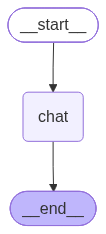

In [47]:
builder = StateGraph(MessagesState)
builder.add_node("chat", chat_creates_memory_node)
builder.add_edge(START, "chat")
builder.add_edge("chat", END)

graph = builder.compile(store=store)

graph


In [52]:
config = {"configurable": {"user_id": "u1"}}

res = graph.invoke({"messages": [{"role": "user", "content": "Hi my name is shreyas"}]}, config)
print("Assistant:", res["messages"][-1].content)

res = graph.invoke({"messages": [{"role": "user", "content": "I teach AI on youtube"}]}, config)
print("Assistant:", res["messages"][-1].content)

res = graph.invoke({"messages": [{"role": "user", "content": "My favorite programming language is Python"}]}, config)
print("Assistant:", res["messages"][-1].content)


Assistant: Noted.
Assistant: Noted.
Assistant: Noted.


In [51]:
items = store.search(("user", "u1", "details"))

for item in items:
    print(item.value['data'])


User's name is Nitish
User teaches AI on YouTube
User's favorite programming language is Python
User's name is Shreyas
